# Support Vector Classifier (SVC) 

### Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

### Load the Dataset

In [3]:
df = pd.read_csv("../../Dataset/iris.csv")
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


### Dataset Information

In [4]:
df.shape

(150, 5)

In [5]:
df.columns

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'target'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [7]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [8]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

In [9]:
print(df["target"].value_counts().sort_index())

target
0    50
1    50
2    50
Name: count, dtype: int64


### Separate Features and Target

In [10]:
X = df.drop(columns=["target"])
y = df["target"]
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


### Test-Train Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

Training samples: (120, 4)
Testing samples: (30, 4)


### Feature Scaling

In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (120, 4)
Testing shape: (30, 4)


### Baseline 

In [13]:
svm_model = SVC(kernel="linear", C=1.0)
svm_model.fit(X_train_scaled, y_train)
print("Model trained successfully.")

Model trained successfully.


### Prediction

In [14]:
y_pred = svm_model.predict(X_test_scaled)
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})
comparison.head(20)

,Actual,Predicted
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


### Evaluation

In [15]:
accuracy = accuracy_score(y_test, y_pred)
print("Baseline Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Baseline Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        10
           2       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


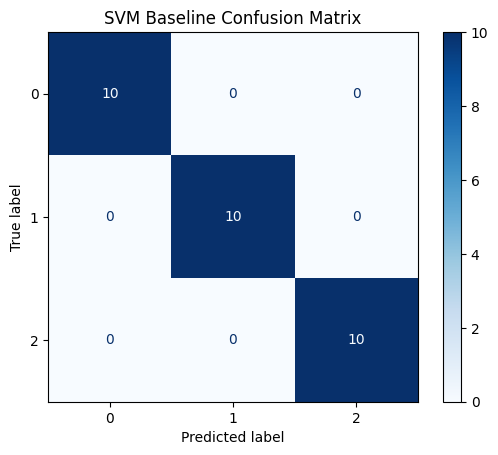

In [16]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
display = ConfusionMatrixDisplay(confusion_matrix=cm)
display.plot(cmap="Blues")
plt.title("SVM Baseline Confusion Matrix")
plt.show()

## Kernals

In [17]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
kernel_results = []
for kernel in kernels:
    model = SVC(kernel=kernel, C=1.0)
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    kernel_results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, predictions)
    })
kernel_results = pd.DataFrame(kernel_results)
kernel_results.sort_values(
    by="Accuracy",
    ascending=False
)

,Kernel,Accuracy
0,linear,1.000000
2,rbf,0.966667
1,poly,0.900000
3,sigmoid,0.900000


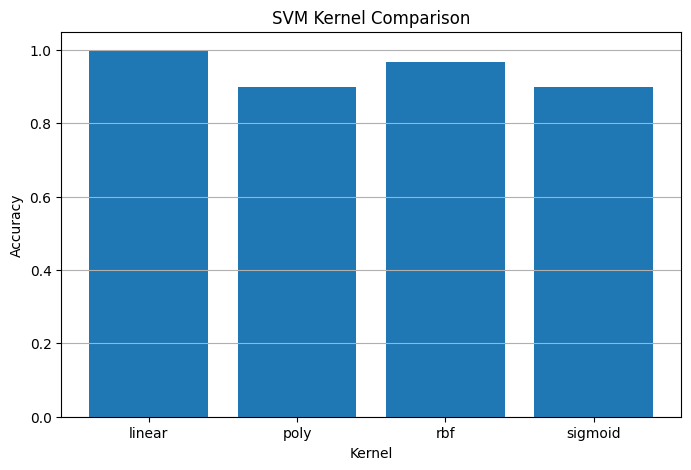

In [18]:
plt.figure(figsize=(8, 5))
plt.bar(kernel_results["Kernel"], kernel_results["Accuracy"])
plt.xlabel("Kernel")
plt.ylabel("Accuracy")
plt.title("SVM Kernel Comparison")
plt.grid(axis="y")
plt.show()

In [19]:
param_grid = [
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10, 100]
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto", 0.01, 0.1, 1]
    },
    {
        "kernel": ["poly"],
        "C": [0.1, 1, 10],
        "gamma": ["scale", "auto"],
        "degree": [2, 3, 4]
    },
    {
        "kernel": ["sigmoid"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", "auto", 0.01, 0.1]
    }
]

In [20]:
svm = SVC()
grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    refit=True,
    verbose=1
)
grid.fit(X_train_scaled, y_train)
print("Model Trained")

Fitting 5 folds for each of 58 candidates, totalling 290 fits


Model Trained


In [21]:
print("Best Parameters:")
print(grid.best_params_)
print("\nBest Cross-Validation Accuracy:")
print(round(grid.best_score_, 4))

Best Parameters:
{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}

Best Cross-Validation Accuracy:
0.9833


In [22]:
cv_results = pd.DataFrame(grid.cv_results_)
cv_results[
    [
        "param_kernel",
        "param_C",
        "param_gamma",
        "param_degree",
        "mean_test_score",
        "rank_test_score"
    ]
].sort_values(
    by="rank_test_score"
).head(10)

,param_kernel,param_C,param_gamma,param_degree,mean_test_score,rank_test_score
12,rbf,1.0,0.1,NaN,0.983333,1
0,linear,0.1,NaN,NaN,0.975000,2
16,rbf,10.0,0.01,NaN,0.975000,2
38,poly,10.0,scale,3.0,0.975000,2
39,poly,10.0,auto,3.0,0.975000,2
56,sigmoid,100.0,0.01,NaN,0.975000,2
1,linear,1.0,NaN,NaN,0.975000,2
52,sigmoid,10.0,0.01,NaN,0.975000,2
49,sigmoid,1.0,0.1,NaN,0.966667,9
21,rbf,100.0,0.01,NaN,0.966667,9


In [23]:
best_svm = grid.best_estimator_
y_pred_best = best_svm.predict(X_test_scaled)
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_best
})
comparison.head(20)

,Actual,Predicted
0,0,0
1,2,2
2,1,1
3,1,1
4,0,0
5,1,1
6,0,0
7,0,0
8,2,2
9,1,1


In [24]:
accuracy = accuracy_score(y_test, y_pred_best)
print("Best Kernel:", best_svm.kernel)
print("Test Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Best Kernel: rbf
Test Accuracy: 0.9667

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



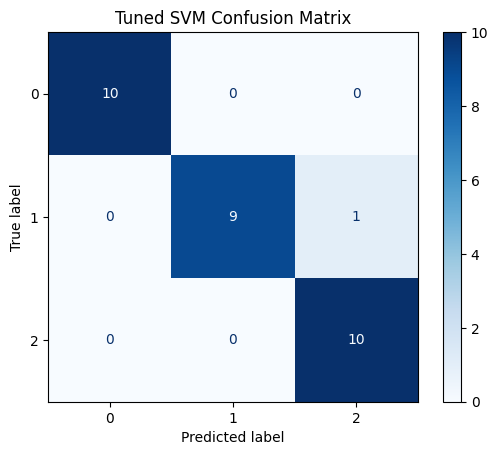

In [25]:
cm = confusion_matrix(y_test, y_pred_best)
display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot(cmap="Blues")
plt.title("Tuned SVM Confusion Matrix")
plt.show()

In [26]:
baseline_accuracy = accuracy_score(y_test, svm_model.predict(X_test_scaled))
tuned_accuracy = accuracy_score(y_test, y_pred_best)
results = pd.DataFrame({
    "Model": ["Baseline SVM", "Tuned SVM"],
    "Test Accuracy": [baseline_accuracy, tuned_accuracy]
})
results

,Model,Test Accuracy
0,Baseline SVM,1.000000
1,Tuned SVM,0.966667
